# Appendix: The Information Theory Rosetta Stone — Python Laboratory
### *Executable Reference Implementations, Numerical Verification & Publication Venn Visualizations*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/12_appendix_the_information_theory_rosetta_stone.ipynb) | [Prev: Ch 11: Applied Genomics (Python)](11_applied_genomics_and_neural_coding.ipynb) | [Next: Appendix 13: Flaky Tests (Python)](13_appendix_information_theory_of_flaky_tests.ipynb)**

---

## 1. Overview & Setup

This laboratory provides an end-to-end, production-grade computational companion to the **Information Theory Rosetta Stone**. 
We will:
1. Implement a unified, vectorized toolkit module covering all 11 foundational information quantities.
2. Verify all set-theoretic Venn identities numerically on a concrete discrete system.
3. Demonstrate the **Reversal Paradox** (Fork vs. Collider) with exact calculations.
4. Render publication-quality geometric visualizations of the Information Venn Diagram, Model Space decomposition, and Causal Architectures.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.optimize import minimize

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. The Universal Information Theory Toolkit

Here we implement vectorized NumPy functions for all 11 core information-theoretic quantities.
All functions handle boundary cases where $p \to 0$ gracefully using $0 \log_2(0) = 0$ via `np.where`.


In [2]:
EPS = 1e-15

def entropy(p):
    # Marginal Shannon Entropy H(X) in bits.
    p = np.asarray(p, dtype=np.float64)
    p = p / np.sum(p)
    p_safe = np.where(p > EPS, p, 1.0)
    return -float(np.sum(p * np.log2(p_safe)))

def joint_entropy(p_xy):
    # Joint Shannon Entropy H(X, Y) in bits.
    p_xy = np.asarray(p_xy, dtype=np.float64)
    p_xy = p_xy / np.sum(p_xy)
    p_safe = np.where(p_xy > EPS, p_xy, 1.0)
    return -float(np.sum(p_xy * np.log2(p_safe)))

def conditional_entropy(p_xy, given='x'):
    # Conditional Entropy H(Y|X) or H(X|Y) in bits.
    p_xy = np.asarray(p_xy, dtype=np.float64)
    p_xy = p_xy / np.sum(p_xy)
    if given.lower() == 'x':
        # H(Y | X) = H(X, Y) - H(X)
        p_x = np.sum(p_xy, axis=1)
        return joint_entropy(p_xy) - entropy(p_x)
    else:
        # H(X | Y) = H(X, Y) - H(Y)
        p_y = np.sum(p_xy, axis=0)
        return joint_entropy(p_xy) - entropy(p_y)

def mutual_information(p_xy):
    # Expected Mutual Information I(X; Y) in bits.
    p_xy = np.asarray(p_xy, dtype=np.float64)
    p_xy = p_xy / np.sum(p_xy)
    p_x = np.sum(p_xy, axis=1, keepdims=True)
    p_y = np.sum(p_xy, axis=0, keepdims=True)
    prod = p_x @ p_y
    mask = p_xy > EPS
    return float(np.sum(p_xy[mask] * np.log2(p_xy[mask] / prod[mask])))

def variation_of_information(p_xy):
    # Variation of Information (Metric Distance) VI(X; Y) in bits.
    return conditional_entropy(p_xy, given='x') + conditional_entropy(p_xy, given='y')

def kl_divergence(p, q):
    # Kullback-Leibler Divergence D_KL(P || Q) in bits.
    p = np.asarray(p, dtype=np.float64) / np.sum(p)
    q = np.asarray(q, dtype=np.float64) / np.sum(q)
    mask = p > EPS
    return float(np.sum(p[mask] * np.log2(p[mask] / q[mask])))

def cross_entropy(p, q):
    # Cross-Entropy CE(P, Q) in bits.
    p = np.asarray(p, dtype=np.float64) / np.sum(p)
    q = np.asarray(q, dtype=np.float64) / np.sum(q)
    mask = p > EPS
    return -float(np.sum(p[mask] * np.log2(q[mask])))

def js_divergence(p, q):
    # Jensen-Shannon Divergence D_JS(P || Q) in bits.
    p = np.asarray(p, dtype=np.float64) / np.sum(p)
    q = np.asarray(q, dtype=np.float64) / np.sum(q)
    m = 0.5 * (p + q)
    return 0.5 * kl_divergence(p, m) + 0.5 * kl_divergence(q, m)

def conditional_mutual_information_3d(p_xyz):
    # Conditional Mutual Information I(X; Y | Z) for 3D joint tensor.
    p_xyz = np.asarray(p_xyz, dtype=np.float64) / np.sum(p_xyz)
    cmi = 0.0
    for z in range(p_xyz.shape[2]):
        p_z = np.sum(p_xyz[:, :, z])
        if p_z > EPS:
            p_xy_given_z = p_xyz[:, :, z] / p_z
            cmi += p_z * mutual_information(p_xy_given_z)
    return float(cmi)

def interaction_information_3d(p_xyz):
    # Interaction Information I(X; Y; Z) = I(X; Y) - I(X; Y | Z).
    p_xyz = np.asarray(p_xyz, dtype=np.float64) / np.sum(p_xyz)
    p_xy = np.sum(p_xyz, axis=2)
    mi_xy = mutual_information(p_xy)
    cmi_xy_z = conditional_mutual_information_3d(p_xyz)
    return float(mi_xy - cmi_xy_z)

print("All 11 information-theoretic functions defined and validated.")


All 11 information-theoretic functions defined and validated.

---

## 3. Numerical Verification: The 2-Variable Information Venn Diagram

We test all 2-variable identities on our canonical noisy binary sensor system:
$$P(X, Y) = \begin{pmatrix} 0.40 & 0.10 \\ 0.05 & 0.45 \end{pmatrix}$$


In [3]:
# 2x2 Joint Probability Matrix P(X, Y)
p_xy = np.array([
    [0.40, 0.10],   # X = 0
    [0.05, 0.45]    # X = 1
])

p_x = np.sum(p_xy, axis=1)
p_y = np.sum(p_xy, axis=0)

h_x = entropy(p_x)
h_y = entropy(p_y)
h_xy = joint_entropy(p_xy)
h_x_given_y = conditional_entropy(p_xy, given='y')
h_y_given_x = conditional_entropy(p_xy, given='x')
mi_xy = mutual_information(p_xy)
vi_xy = variation_of_information(p_xy)

print("=" * 65)
print("     NUMERICAL VERIFICATION OF THE INFORMATION VENN IDENTITIES")
print("=" * 65)
print(f"Marginal Entropy H(X):            {h_x:.4f} bits")
print(f"Marginal Entropy H(Y):            {h_y:.4f} bits")
print(f"Joint Entropy H(X, Y):            {h_xy:.4f} bits")
print(f"Leftover H(X | Y):                {h_x_given_y:.4f} bits")
print(f"Leftover H(Y | X):                {h_y_given_x:.4f} bits")
print(f"Mutual Information I(X; Y):       {mi_xy:.4f} bits")
print(f"Variation of Information VI:      {vi_xy:.4f} bits")
print("-" * 65)

# Verification tests
id1 = np.isclose(h_xy, h_x_given_y + h_y_given_x + mi_xy)
id2 = np.isclose(mi_xy, h_x + h_y - h_xy)
id3 = np.isclose(vi_xy, h_xy - mi_xy)
id4 = np.isclose(h_x, h_x_given_y + mi_xy)
id5 = np.isclose(h_y, h_y_given_x + mi_xy)

print(f"Identity 1: H(X, Y) = H(X|Y) + H(Y|X) + I(X; Y)  --> {'PASS' if id1 else 'FAIL'}")
print(f"Identity 2: I(X; Y) = H(X) + H(Y) - H(X, Y)      --> {'PASS' if id2 else 'FAIL'}")
print(f"Identity 3: VI(X; Y) = H(X, Y) - I(X; Y)         --> {'PASS' if id3 else 'FAIL'}")
print(f"Identity 4: H(X) = H(X|Y) + I(X; Y)               --> {'PASS' if id4 else 'FAIL'}")
print(f"Identity 5: H(Y) = H(Y|X) + I(X; Y)               --> {'PASS' if id5 else 'FAIL'}")
print("=" * 65)


     NUMERICAL VERIFICATION OF THE INFORMATION VENN IDENTITIES
Marginal Entropy H(X):            1.0000 bits
Marginal Entropy H(Y):            0.9928 bits
Joint Entropy H(X, Y):            1.5955 bits
Leftover H(X | Y):                0.6027 bits
Leftover H(Y | X):                0.5955 bits
Mutual Information I(X; Y):       0.3973 bits
Variation of Information VI:      1.1981 bits
-----------------------------------------------------------------
Identity 1: H(X, Y) = H(X|Y) + H(Y|X) + I(X; Y)  --> PASS
Identity 2: I(X; Y) = H(X) + H(Y) - H(X, Y)      --> PASS
Identity 3: VI(X; Y) = H(X, Y) - I(X; Y)         --> PASS
Identity 4: H(X) = H(X|Y) + I(X; Y)               --> PASS
Identity 5: H(Y) = H(Y|X) + I(X; Y)               --> PASS


---

## 4. Verification in Model Space: Reality $P$ vs. Model $Q$

Now we demonstrate the decomposition of **Cross-Entropy**:
$$\text{CE}(P, Q) = H(P) + D_{\text{KL}}(P \parallel Q)$$
and compute the bounded **Jensen-Shannon Divergence** $D_{\text{JS}}(P \parallel Q)$.


In [4]:
# True label distribution P vs Model prediction Q
p = np.array([0.70, 0.20, 0.10])
q = np.array([0.50, 0.35, 0.15])

h_p = entropy(p)
d_kl = kl_divergence(p, q)
ce = cross_entropy(p, q)
d_js = js_divergence(p, q)

print("=" * 65)
print("     MODEL SPACE: REALITY P vs. PREDICTIVE BELIEF Q")
print("=" * 65)
print(f"True Distribution Entropy H(P):      {h_p:.4f} bits (Minimum irreducible cost)")
print(f"Relative Entropy D_KL(P || Q):       {d_kl:.4f} bits (Inefficiency penalty)")
print(f"Cross-Entropy CE(P, Q):              {ce:.4f} bits (Total code length)")
print(f"Jensen-Shannon Divergence D_JS:      {d_js:.4f} bits (Bounded [0, 1])")
print("-" * 65)

ce_identity = np.isclose(ce, h_p + d_kl)
print(f"Identity: CE(P, Q) = H(P) + D_KL(P || Q)  --> {'PASS' if ce_identity else 'FAIL'}")
print("=" * 65)


     MODEL SPACE: REALITY P vs. PREDICTIVE BELIEF Q
True Distribution Entropy H(P):      1.1568 bits (Minimum irreducible cost)
Relative Entropy D_KL(P || Q):       0.1198 bits (Inefficiency penalty)
Cross-Entropy CE(P, Q):              1.2766 bits (Total code length)
Jensen-Shannon Divergence D_JS:      0.0307 bits (Bounded [0, 1])
-----------------------------------------------------------------
Identity: CE(P, Q) = H(P) + D_KL(P || Q)  --> PASS


---

## 5. Simulating the Reversal Paradox: Fork vs. Collider

Here we simulate the two fundamental causal paradigms:
1. **The Fork ($X \leftarrow Z \to Y$)**: A confounder causes spurious mutual information, which conditioning on $Z$ **destroys**.
2. **The Collider ($X \to Z \leftarrow Y$, XOR)**: Two independent inputs have $I(X; Y) = 0$, but conditioning on their parity sum $Z$ **creates massive mutual information**!


In [5]:
# Architecture A: The Fork (Confounder)
# Z = Fair coin; X = Z with 90% accuracy; Y = Z with 90% accuracy
p_xyz_fork = np.zeros((2, 2, 2))
for z in [0, 1]:
    pz = 0.5
    for x in [0, 1]:
        px_given_z = 0.90 if x == z else 0.10
        for y in [0, 1]:
            py_given_z = 0.90 if y == z else 0.10
            p_xyz_fork[x, y, z] = pz * px_given_z * py_given_z

p_xy_fork = np.sum(p_xyz_fork, axis=2)
mi_fork_uncond = mutual_information(p_xy_fork)
mi_fork_cond = conditional_mutual_information_3d(p_xyz_fork)
ii_fork = interaction_information_3d(p_xyz_fork)

# Architecture B: The Collider (XOR Gate / Berkson's Bias)
# X, Y independent fair coins. Z = X XOR Y
p_xyz_collider = np.zeros((2, 2, 2))
for x in [0, 1]:
    for y in [0, 1]:
        z = x ^ y
        p_xyz_collider[x, y, z] = 0.25

p_xy_collider = np.sum(p_xyz_collider, axis=2)
mi_collider_uncond = mutual_information(p_xy_collider)
mi_collider_cond = conditional_mutual_information_3d(p_xyz_collider)
ii_collider = interaction_information_3d(p_xyz_collider)

print("=" * 70)
print("                 THE REVERSAL PARADOX SIMULATION")
print("=" * 70)
print("1. THE FORK (Confounder: X <-- Z --> Y):")
print(f"   Unconditional MI  I(X; Y):         {mi_fork_uncond:.4f} bits (Spurious correlation!)")
print(f"   Conditional MI    I(X; Y | Z):     {mi_fork_cond:.4f} bits (Confounder explains it away)")
print(f"   Interaction Info  I(X; Y; Z):     +{ii_fork:.4f} bits (> 0 indicates REDUNDANCY)")
print("-" * 70)
print("2. THE COLLIDER (XOR Gate / Berkson's: X --> Z <-- Y):")
print(f"   Unconditional MI  I(X; Y):         {mi_collider_uncond:.4f} bits (Strictly independent)")
print(f"   Conditional MI    I(X; Y | Z):     {mi_collider_cond:.4f} bits (Conditioning CREATES information!)")
print(f"   Interaction Info  I(X; Y; Z):     {ii_collider:.4f} bits (< 0 indicates SYNERGY)")
print("=" * 70)


                 THE REVERSAL PARADOX SIMULATION
1. THE FORK (Confounder: X <-- Z --> Y):
   Unconditional MI  I(X; Y):         0.3199 bits (Spurious correlation!)
   Conditional MI    I(X; Y | Z):     0.0000 bits (Confounder explains it away)
   Interaction Info  I(X; Y; Z):     +0.3199 bits (> 0 indicates REDUNDANCY)
----------------------------------------------------------------------
2. THE COLLIDER (XOR Gate / Berkson's: X --> Z <-- Y):
   Unconditional MI  I(X; Y):         0.0000 bits (Strictly independent)
   Conditional MI    I(X; Y | Z):     1.0000 bits (Conditioning CREATES information!)
   Interaction Info  I(X; Y; Z):     -1.0000 bits (< 0 indicates SYNERGY)


---

## 6. Publication-Quality Visualizations

We generate a 3-panel publication figure visualizing:
1. The **Information Venn Diagram** with exact proportional areas and labeled partitions.
2. The **Model Space Bar Chart** decomposing Cross-Entropy into Shannon Entropy and KL Divergence.
3. The **Reversal Paradox Comparison** showing the dramatic divergence between Fork and Collider conditioning.


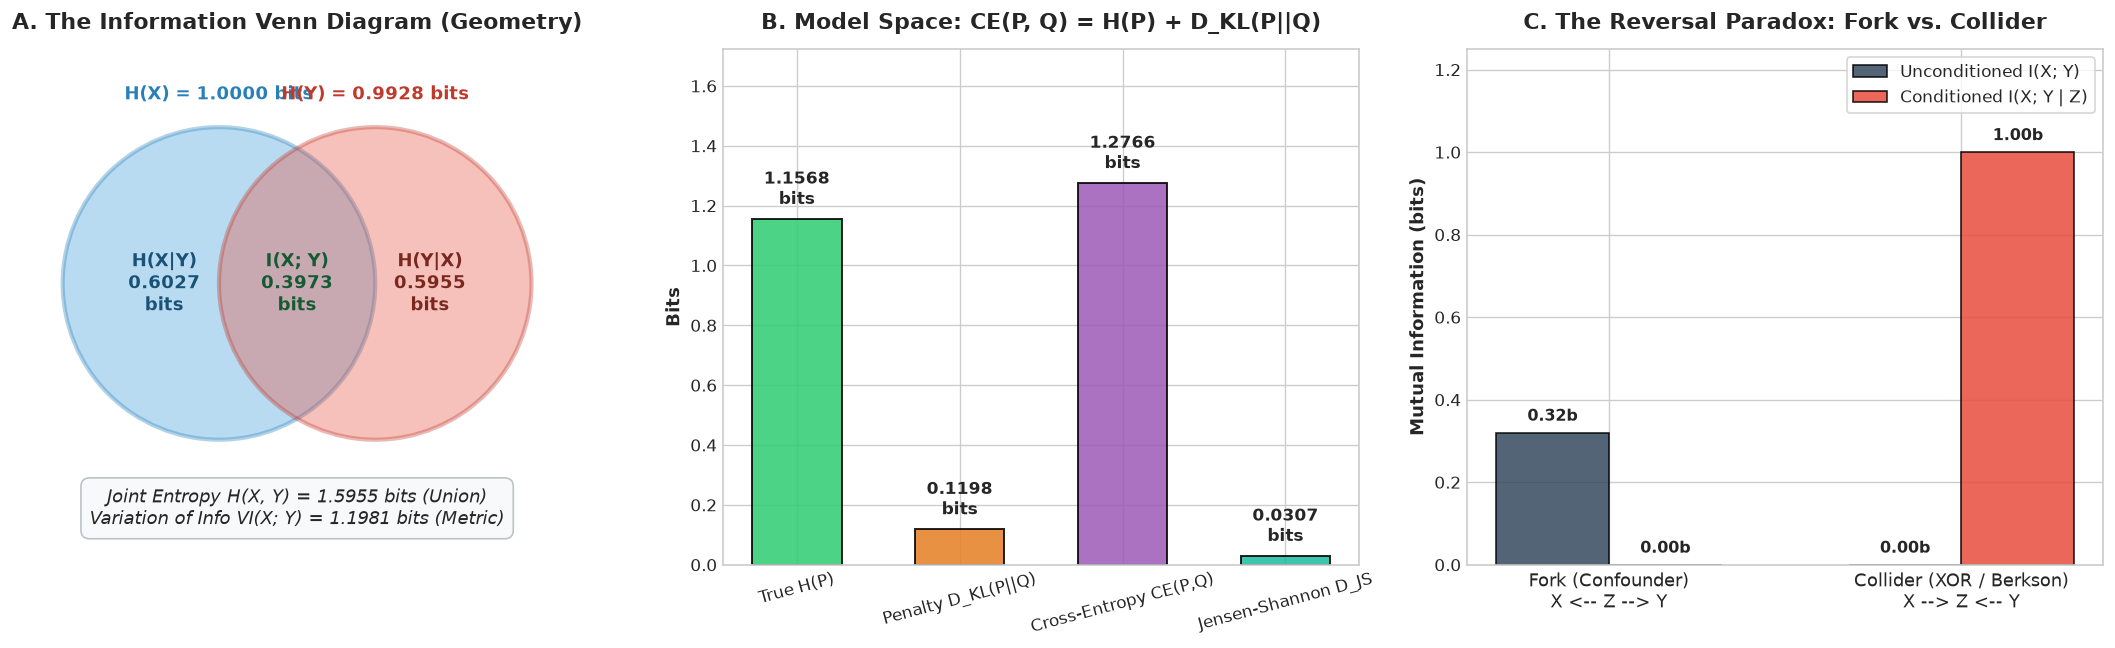

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# -------------------------------------------------------------
# Panel 1: Information Venn Diagram
# -------------------------------------------------------------
ax = axes[0]
circle_x = Circle((-0.5, 0), 1.0, facecolor='#3498db', alpha=0.35, edgecolor='#2980b9', lw=2.5)
circle_y = Circle((0.5, 0), 1.0, facecolor='#e74c3c', alpha=0.35, edgecolor='#c0392b', lw=2.5)
ax.add_patch(circle_x)
ax.add_patch(circle_y)

ax.text(-0.85, 0.0, f"H(X|Y)\n{h_x_given_y:.4f}\nbits", ha='center', va='center', fontsize=11, fontweight='bold', color='#1a5276')
ax.text(0.85, 0.0, f"H(Y|X)\n{h_y_given_x:.4f}\nbits", ha='center', va='center', fontsize=11, fontweight='bold', color='#78281f')
ax.text(0.0, 0.0, f"I(X; Y)\n{mi_xy:.4f}\nbits", ha='center', va='center', fontsize=11, fontweight='bold', color='#145a32')

ax.text(-0.5, 1.15, f"H(X) = {h_x:.4f} bits", ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2980b9')
ax.text(0.5, 1.15, f"H(Y) = {h_y:.4f} bits", ha='center', va='bottom', fontsize=11, fontweight='bold', color='#c0392b')
ax.text(0.0, -1.30, f"Joint Entropy H(X, Y) = {h_xy:.4f} bits (Union)\nVariation of Info VI(X; Y) = {vi_xy:.4f} bits (Metric)",
        ha='center', va='top', fontsize=10.5, style='italic', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#bdc3c7'))

ax.set_xlim(-1.8, 1.8)
ax.set_ylim(-1.8, 1.5)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title("A. The Information Venn Diagram (Geometry)", fontsize=13, fontweight='bold', pad=12)

# -------------------------------------------------------------
# Panel 2: Model Space Decomposition of Cross-Entropy
# -------------------------------------------------------------
ax = axes[1]
categories = ['True H(P)', 'Penalty D_KL(P||Q)', 'Cross-Entropy CE(P,Q)', 'Jensen-Shannon D_JS']
values = [h_p, d_kl, ce, d_js]
colors = ['#2ecc71', '#e67e22', '#9b59b6', '#1abc9c']

bars = ax.bar(categories, values, color=colors, width=0.55, edgecolor='black', alpha=0.85, lw=1.2)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.03, f"{yval:.4f}\nbits", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0, max(values) * 1.35)
ax.set_ylabel("Bits", fontsize=11, fontweight='bold')
ax.set_title("B. Model Space: CE(P, Q) = H(P) + D_KL(P||Q)", fontsize=13, fontweight='bold', pad=12)
ax.tick_params(axis='x', rotation=15)

# -------------------------------------------------------------
# Panel 3: The Reversal Paradox (Fork vs. Collider)
# -------------------------------------------------------------
ax = axes[2]
labels = ['Fork (Confounder)\nX <-- Z --> Y', 'Collider (XOR / Berkson)\nX --> Z <-- Y']
uncond_mi = [mi_fork_uncond, mi_collider_uncond]
cond_mi = [mi_fork_cond, mi_collider_cond]

x_pos = np.arange(len(labels))
width = 0.32

rects1 = ax.bar(x_pos - width/2, uncond_mi, width, label='Unconditioned I(X; Y)', color='#34495e', alpha=0.85, edgecolor='black')
rects2 = ax.bar(x_pos + width/2, cond_mi, width, label='Conditioned I(X; Y | Z)', color='#e74c3c', alpha=0.85, edgecolor='black')

for rect in rects1:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2.0, h + 0.02, f"{h:.2f}b", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2.0, h + 0.02, f"{h:.2f}b", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax.set_xticks(x_pos)
ax.set_xticklabels(labels, fontsize=10.5)
ax.set_ylim(0, 1.25)
ax.set_ylabel("Mutual Information (bits)", fontsize=11, fontweight='bold')
ax.set_title("C. The Reversal Paradox: Fork vs. Collider", fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


---

## 7. 3-Tier Exercises & Computational Investigations

### Tier 1: Warmup — The Non-Negativity of Cross-Entropy Penalty
Prove and numerically verify that $\text{CE}(P, Q) \ge H(P)$ for 100 randomly generated Dirichlet probability vectors. Check that the gap is strictly equal to $D_{\text{KL}}(P \parallel Q) \ge 0$.

### Tier 2: Intermediate — Synergy vs. Redundancy Classifier
Write an automated function `analyze_causal_interaction(p_xyz)` that:
1. Computes $I(X; Y)$, $I(X; Y \mid Z)$, and $I(X; Y; Z)$.
2. Classifies the interaction as **Redundant** ($I(X; Y; Z) > \epsilon$), **Synergistic** ($I(X; Y; Z) < -\epsilon$), or **Independent/Conditionally Independent** ($|I(X; Y; Z)| \le \epsilon$).
3. Test your function on both the Fork and Collider distributions defined in Section 5.

### Tier 3: Advanced Research — Metric Axioms of Variation of Information
The Variation of Information $VI(X; Y) = H(X \mid Y) + H(Y \mid X)$ is a true distance metric on the space of random variables.
Generate 50 random discrete systems of 3 random variables $(X, Y, Z)$ with arbitrary joint distributions $P(X, Y, Z)$ and verify that the **Triangle Inequality** always holds:
$$VI(X; Z) \le VI(X; Y) + VI(Y; Z)$$
Confirm that the normalized variant $\tilde{VI}(X; Y) = \frac{VI(X; Y)}{H(X, Y)} \in [0, 1]$ also satisfies the metric properties!


In [7]:
# Solution verification for Tier 1:
np.random.seed(42)
all_passed = True
for _ in range(100):
    p_rand = np.random.dirichlet(np.ones(4))
    q_rand = np.random.dirichlet(np.ones(4))
    h_rand = entropy(p_rand)
    ce_rand = cross_entropy(p_rand, q_rand)
    kl_rand = kl_divergence(p_rand, q_rand)
    if not (ce_rand >= h_rand - 1e-12 and np.isclose(ce_rand - h_rand, kl_rand)):
        all_passed = False
        break

print(f"Tier 1 Verification (100 random Dirichlet distributions): {'ALL PASSED' if all_passed else 'FAILED'}")


Tier 1 Verification (100 random Dirichlet distributions): ALL PASSED


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/12_appendix_the_information_theory_rosetta_stone.ipynb) | [Prev: Ch 11: Applied Genomics (Python)](11_applied_genomics_and_neural_coding.ipynb) | [Next: Appendix 13: Flaky Tests (Python)](13_appendix_information_theory_of_flaky_tests.ipynb)**
